In [1]:
import pandas as pd
from io import StringIO
import numpy as np

data = """date_pr,date_gr,open,high,low,close
1405_07_16,2026_10_08,265.685,268.200,265.200,266.200
1405_07_15,2026_10_07,267.995,268.500,261.660,263.200
1405_07_14,2026_10_06,269.000,270.520,267.760,268.820
1405_07_13,2026_10_05,268.710,271.815,267.960,268.700
1405_07_12,2026_10_04,270.000,272.020,265.760,268.300
1405_07_11,2026_10_03,265.275,268.520,265.060,267.900
1405_07_09,2026_10_01,254.900,258.520,254.660,258.465
1405_07_08,2026_09_30,253.470,256.520,253.460,254.700
1405_07_07,2026_09_29,249.995,253.720,249.360,253.700
1405_07_06,2026_09_28,240.500,245.020,240.260,244.800
1405_07_05,2026_09_27,234.600,236.020,234.060,235.000
1405_07_04,2026_09_26,233.515,234.820,232.960,233.300
1405_07_02,2026_09_24,235.775,236.320,234.060,234.615
1405_07_01,2026_09_23,230.505,232.720,230.260,231.705
1405_06_31,2026_09_22,234.810,235.520,232.560,233.200
1405_06_30,2026_09_21,231.000,231.920,230.760,230.800
1405_06_29,2026_09_20,230.185,232.220,230.160,230.600
1405_06_28,2026_09_19,226.600,230.320,226.560,230.275
1405_06_26,2026_09_17,230.515,230.520,227.860,227.900
1405_06_25,2026_09_16,229.700,231.120,229.360,230.500
1405_06_24,2026_09_15,231.610,232.520,229.760,230.395
1405_06_23,2026_09_14,231.570,234.620,231.260,231.300
1405_06_22,2026_09_13,233.800,233.800,228.560,228.600
1405_06_21,2026_09_12,235.600,237.020,233.660,233.900
1405_06_19,2026_09_10,234.300,236.020,233.860,235.975
1405_06_18,2026_09_09,227.700,232.820,227.660,232.700
1405_06_17,2026_09_08,223.265,226.720,223.260,226.700
1405_06_16,2026_09_07,225.100,225.320,222.060,222.100
1405_06_15,2026_09_06,228.705,228.720,222.960,223.000
1405_06_14,2026_09_05,223.305,227.220,223.260,227.205
1405_06_12,2026_09_03,221.420,221.820,220.260,221.060
1405_06_11,2026_09_02,217.200,220.520,216.700,219.900
1405_06_10,2026_09_01,210.020,214.220,209.960,214.000
1405_06_09,2026_08_31,207.695,209.920,206.760,209.300
1405_06_07,2026_08_29,202.700,206.220,202.695,206.010
1405_06_05,2026_08_27,200.295,202.220,200.160,200.600
1405_06_04,2026_08_26,199.820,201.820,198.960,200.500
1405_06_03,2026_08_25,204.620,204.820,199.960,200.500
1405_06_02,2026_08_24,201.970,203.020,201.670,202.195
1405_06_01,2026_08_23,198.185,200.720,197.380,199.900
1405_05_31,2026_08_22,190.500,192.920,189.880,192.700
1405_05_29,2026_08_20,188.790,189.820,188.780,189.400
1405_05_28,2026_08_19,187.515,189.420,187.480,188.600
1405_05_27,2026_08_18,187.205,187.220,186.980,187.010
1405_05_26,2026_08_17,186.800,186.820,185.280,186.500
1405_05_25,2026_08_16,186.900,186.910,185.480,186.680
1405_05_24,2026_08_15,187.585,187.720,186.980,187.005
1405_05_20,2026_08_11,185.210,188.020,185.180,187.800
1405_05_19,2026_08_10,185.710,186.720,184.680,185.600
1405_05_18,2026_08_09,185.710,186.720,184.680,185.400
1405_05_17,2026_08_08,187.995,188.020,185.480,185.900
1405_05_15,2026_08_06,188.005,188.220,186.780,188.020
1405_05_14,2026_08_05,189.000,189.220,186.680,188.000
1405_05_12,2026_08_03,191.010,193.020,190.980,192.880
1405_05_11,2026_08_02,191.105,194.000,190.780,191.000
1405_05_10,2026_08_01,192.820,194.520,192.780,193.700
1405_05_08,2026_07_30,193.585,193.620,192.080,192.400
1405_05_07,2026_07_29,192.500,194.020,192.480,193.500
1405_05_06,2026_07_28,187.000,191.220,186.980,190.200
1405_05_05,2026_07_27,186.390,190.220,186.380,188.000
1405_05_04,2026_07_26,189.200,189.200,185.380,186.500
1405_05_03,2026_07_25,191.190,191.320,189.480,189.700
1405_05_01,2026_07_23,191.795,193.220,191.780,193.115
1405_04_31,2026_07_22,190.085,192.620,190.080,192.405
1405_04_30,2026_07_21,187.800,191.020,187.780,190.300
1405_04_29,2026_07_20,190.500,190.520,187.480,187.700
1405_04_28,2026_07_19,195.000,195.020,192.380,193.000
1405_04_27,2026_07_18,191.290,194.520,191.280,194.500
1405_04_25,2026_07_16,189.210,189.220,187.380,188.600
1405_04_24,2026_07_15,183.480,188.820,183.480,188.200
1405_04_23,2026_07_14,181.315,184.620,181.280,184.110
1405_04_22,2026_07_13,180.200,181.020,179.580,180.985
1405_04_21,2026_07_12,177.500,179.820,177.480,179.600
1405_04_20,2026_07_11,182.510,182.520,177.980,178.200
1405_04_18,2026_07_09,180.100,182.620,180.080,181.620
1405_04_17,2026_07_08,175.985,181.220,175.980,180.195
1405_04_16,2026_07_07,175.710,177.020,174.980,176.685
1405_04_15,2026_07_06,175.595,176.028,175.180,175.700
1405_04_14,2026_07_05,174.610,175.820,174.580,175.600
1405_04_11,2026_07_02,174.990,176.020,174.780,175.395
1405_04_10,2026_07_01,173.000,176.520,172.980,174.300
1405_04_09,2026_06_30,171.695,172.720,170.680,172.500
1405_04_08,2026_06_29,173.400,173.620,170.680,170.900
1405_04_07,2026_06_28,166.795,172.920,166.780,172.690
1405_04_06,2026_06_27,166.285,168.020,166.280,166.815
1405_04_02,2026_06_23,157.985,162.020,157.980,161.500
1405_04_01,2026_06_22,160.290,160.520,157.480,158.000
1405_03_31,2026_06_21,160.295,160.320,158.980,159.600
1405_03_30,2026_06_20,161.485,163.520,160.780,160.800
1405_03_28,2026_06_18,156.485,157.520,156.480,156.500
1405_03_27,2026_06_17,153.505,161.015,153.480,159.500
1405_03_26,2026_06_16,160.490,160.520,154.980,155.000
1405_03_25,2026_06_15,171.000,171.020,161.480,161.510
1405_03_24,2026_06_14,169.990,172.020,168.980,171.205
1405_03_23,2026_06_13,181.005,181.020,171.980,172.010
1405_03_21,2026_06_11,178.780,180.520,178.780,180.180
1405_03_20,2026_06_10,175.805,178.520,175.780,178.510
1405_03_19,2026_06_09,176.980,177.020,175.180,175.300
1405_03_18,2026_06_08,178.215,178.820,177.280,177.400
1405_03_17,2026_06_07,174.795,178.020,174.780,178.010
1405_03_16,2026_06_06,173.500,175.520,173.480,174.990
1405_03_13,2026_06_03,174.510,174.820,173.780,174.420
1405_03_12,2026_06_02,174.495,175.520,173.980,174.520
1405_03_11,2026_06_01,171.515,177.020,171.480,176.180
1405_03_10,2026_05_31,170.990,171.020,169.980,170.485
1405_03_09,2026_05_30,173.980,174.020,169.980,170.490
1405_03_07,2026_05_28,172.395,174.520,172.380,174.500
1405_03_05,2026_05_26,173.385,173.420,171.880,172.400
1405_03_04,2026_05_25,172.395,175.420,172.380,173.910
1405_03_03,2026_05_24,176.720,176.720,168.380,169.910
1405_03_02,2026_05_23,179.210,179.420,177.385,177.420
1405_02_31,2026_05_21,179.915,179.920,178.680,179.080
1405_02_30,2026_05_20,178.410,182.420,178.380,179.910
1405_02_29,2026_05_19,179.420,179.420,177.185,178.400
1405_02_28,2026_05_18,180.920,180.920,178.880,179.920
1405_02_27,2026_05_17,179.905,182.920,179.880,181.390
1405_02_26,2026_05_16,180.390,181.420,179.380,179.400
1405_02_24,2026_05_14,179.415,180.420,178.880,179.890
1405_02_23,2026_05_13,180.410,180.420,177.880,178.895
1405_02_22,2026_05_12,181.390,182.420,179.880,180.400
1405_02_21,2026_05_11,180.420,182.420,179.980,181.905
1405_02_20,2026_05_10,177.880,177.920,175.880,175.880
1405_02_19,2026_05_09,177.900,178.420,177.880,177.890
1405_02_17,2026_05_07,174.385,175.420,173.880,175.420
1405_02_16,2026_05_06,178.920,179.420,174.380,176.380
1405_02_15,2026_05_05,181.890,182.920,179.880,181.380
1405_02_14,2026_05_04,187.905,190.420,179.500,179.500
1405_02_13,2026_05_03,186.920,187.420,186.380,186.410
1405_02_12,2026_05_02,180.890,183.920,180.880,182.410
1405_02_10,2026_04_30,176.915,178.920,176.880,177.910
1405_02_09,2026_04_29,173.920,181.920,173.380,175.390
1405_02_08,2026_04_28,159.420,166.920,159.380,165.890
1405_02_07,2026_04_27,157.400,158.920,156.380,158.890
1405_02_06,2026_04_26,157.420,157.420,156.480,156.495
1405_02_05,2026_04_25,155.000,156.220,153.780,156.000
1405_02_03,2026_04_23,155.210,155.220,154.480,154.990
1405_02_02,2026_04_22,152.510,156.020,152.480,155.220
1405_02_01,2026_04_21,151.220,152.520,151.180,152.520
1405_01_31,2026_04_20,149.000,153.520,148.980,151.190
1405_01_30,2026_04_19,147.640,153.820,147.640,149.020
1405_01_29,2026_04_18,152.090,152.120,147.180,147.680
1405_01_27,2026_04_16,152.520,152.520,152.080,152.120
1405_01_26,2026_04_15,159.080,159.120,152.480,152.480
1405_01_25,2026_04_14,159.080,159.120,159.080,159.110
1405_01_24,2026_04_13,156.560,159.120,156.540,159.110
1405_01_23,2026_04_12,153.600,157.020,153.600,156.570
1405_01_22,2026_04_11,156.500,156.520,153.600,153.610
1405_01_20,2026_04_09,154.320,157.020,153.910,156.490
1405_01_19,2026_04_08,156.990,157.020,153.310,154.340
1405_01_18,2026_04_07,160.500,160.500,160.500,160.500
1405_01_16,2026_04_05,158.560,158.580,146.980,157.000
1405_01_15,2026_04_04,158.580,158.580,158.540,158.570
1405_01_13,2026_04_02,158.555,158.580,158.540,158.560
1405_01_12,2026_04_01,158.580,158.580,158.540,158.570
1405_01_11,2026_03_31,158.580,158.580,158.540,158.575
1405_01_10,2026_03_30,158.550,158.580,158.540,158.550
1405_01_09,2026_03_29,158.540,158.580,158.540,158.560
1405_01_08,2026_03_28,158.570,158.580,158.540,158.580
1405_01_06,2026_03_26,157.750,158.580,157.720,158.580
1405_01_05,2026_03_25,157.760,157.800,157.720,157.730
1405_01_04,2026_03_24,146.995,157.800,146.980,157.770
1405_01_03,2026_03_23,155.160,160.000,154.650,158.780
1404_12_28,2026_03_19,156.600,159.280,156.600,159.280
1404_12_27,2026_03_18,151.840,156.390,151.840,156.390
1404_12_26,2026_03_17,143.400,145.120,143.400,145.120
1404_12_25,2026_03_16,166.340,166.370,143.700,143.700
1404_12_24,2026_03_15,147.000,147.000,147.000,147.000
1404_12_23,2026_03_14,166.330,166.370,166.330,166.360
1404_12_21,2026_03_12,166.370,166.370,166.330,166.360
1404_12_20,2026_03_11,166.330,166.370,166.330,166.350
1404_12_19,2026_03_10,166.330,166.370,166.330,166.370
1404_12_18,2026_03_09,166.370,166.370,166.330,166.350
1404_12_17,2026_03_08,166.355,166.370,166.330,166.350
1404_12_16,2026_03_07,166.360,166.370,166.330,166.370
1404_12_14,2026_03_05,166.355,166.370,166.330,166.330
1404_12_13,2026_03_04,166.360,166.370,166.330,166.370
1404_12_12,2026_03_03,166.330,166.370,166.330,166.355
1404_12_11,2026_03_02,166.345,166.370,166.330,166.340
1404_12_10,2026_03_01,166.355,166.370,166.330,166.370
1404_12_09,2026_02_28,166.335,166.370,166.330,166.360
1404_12_07,2026_02_26,165.155,165.670,165.030,165.370
1404_12_06,2026_02_25,164.060,165.870,164.030,165.130
1404_12_05,2026_02_24,163.070,164.270,163.030,163.945
1404_12_04,2026_02_23,163.230,163.470,162.330,163.470
1404_12_03,2026_02_22,164.165,164.570,163.230,163.265
1404_12_02,2026_02_21,163.435,165.070,163.430,164.570
1404_11_30,2026_02_19,162.730,163.770,162.730,163.640
1404_11_29,2026_02_18,161.030,162.970,161.030,162.335
1404_11_28,2026_02_17,159.990,162.970,159.980,160.860
1404_11_27,2026_02_16,159.855,160.370,159.130,159.960
1404_11_26,2026_02_15,158.660,160.370,158.630,159.730
1404_11_25,2026_02_14,162.135,162.170,158.380,158.390
1404_11_23,2026_02_12,162.455,162.770,161.730,162.550
1404_11_21,2026_02_10,161.360,163.770,161.330,163.240
1404_11_20,2026_02_09,159.260,161.770,159.230,161.230
1404_11_19,2026_02_08,155.445,159.170,155.430,158.950
1404_11_18,2026_02_07,161.935,161.970,156.430,156.470
1404_11_16,2026_02_05,160.935,162.470,157.230,162.240
1404_11_14,2026_02_03,154.465,157.170,153.430,156.850
1404_11_13,2026_02_02,158.660,158.670,153.230,154.440
1404_11_12,2026_02_01,162.430,162.470,157.430,158.955
1404_11_11,2026_01_31,159.965,164.970,158.230,162.960
1404_11_09,2026_01_29,160.945,164.970,156.430,158.440
1404_11_08,2026_01_28,152.740,159.670,152.730,159.560
1404_11_07,2026_01_27,146.570,151.770,146.530,151.760
1404_11_06,2026_01_26,142.164,146.470,140.034,146.465
1404_11_05,2026_01_25,141.010,142.620,141.000,142.174
1404_11_04,2026_01_24,145.530,145.540,141.000,141.000
1404_11_02,2026_01_22,145.510,145.540,140.300,140.300
1404_11_01,2026_01_21,145.500,145.540,145.500,145.525
1404_10_30,2026_01_20,145.505,145.540,145.500,145.540
1404_10_29,2026_01_19,145.535,145.540,145.500,145.500
1404_10_28,2026_01_18,145.520,145.540,145.500,145.530
1404_10_27,2026_01_17,145.505,145.540,145.500,145.510
1404_10_25,2026_01_15,145.525,145.540,145.500,145.510
1404_10_24,2026_01_14,145.535,145.540,145.500,145.510
1404_10_23,2026_01_13,145.535,145.540,145.500,145.540
1404_10_22,2026_01_12,145.525,145.540,145.500,145.510
1404_10_21,2026_01_11,145.505,145.540,145.500,145.540
1404_10_20,2026_01_10,145.500,145.540,145.500,145.500
1404_10_18,2026_01_08,146.805,147.140,145.400,146.040
1404_10_17,2026_01_07,147.030,147.940,145.460,147.520
1404_10_16,2026_01_06,144.150,147.440,144.140,147.015
1404_10_15,2026_01_05,137.770,143.880,137.740,143.760
1404_10_14,2026_01_04,137.040,138.480,136.740,137.940
1404_10_11,2026_01_01,135.205,135.680,134.040,135.680
1404_10_10,2025_12_31,139.750,139.750,135.540,135.565
1404_10_09,2025_12_30,136.985,139.700,136.980,139.570
1404_10_08,2025_12_29,141.750,141.760,137.580,137.720
1404_10_07,2025_12_28,139.495,144.500,139.460,141.910
1404_10_06,2025_12_27,134.415,138.850,134.410,138.830
1404_10_04,2025_12_25,135.600,135.600,133.760,134.390
1404_10_03,2025_12_24,134.685,136.200,134.060,135.390
1404_10_02,2025_12_23,131.965,134.750,131.965,134.750
1404_10_01,2025_12_22,131.025,132.950,129.960,132.950
1404_09_30,2025_12_21,132.050,132.050,129.810,131.225
1404_09_29,2025_12_20,130.995,132.900,130.960,132.200
1404_09_27,2025_12_18,132.190,132.200,131.610,131.630
1404_09_26,2025_12_17,130.060,132.100,130.060,132.070
1404_09_25,2025_12_16,130.310,130.350,129.210,129.870
1404_09_24,2025_12_15,129.970,131.700,129.970,130.360
1404_09_23,2025_12_14,128.565,129.800,127.510,129.690
1404_09_22,2025_12_13,127.685,129.100,126.560,128.990
1404_09_20,2025_12_11,124.680,125.800,123.860,125.750
1404_09_19,2025_12_10,124.980,125.100,124.110,124.930
1404_09_18,2025_12_09,125.975,126.655,124.310,124.870
1404_09_17,2025_12_08,124.045,126.305,124.015,126.280
1404_09_16,2025_12_07,122.125,124.005,122.115,124.005
1404_09_15,2025_12_06,119.725,122.205,119.715,121.995
1404_09_13,2025_12_04,120.325,120.605,119.515,119.705
1404_09_12,2025_12_03,119.045,120.905,119.015,120.455
1404_09_11,2025_12_02,119.105,119.105,117.815,118.695
1404_09_10,2025_12_01,117.660,119.355,117.630,118.975
1404_09_09,2025_11_30,115.970,117.420,115.930,117.380
1404_09_08,2025_11_29,114.000,115.870,113.980,115.860
1404_09_06,2025_11_27,113.615,114.420,113.580,114.170
1404_09_05,2025_11_26,113.450,113.920,113.180,113.640
1404_09_04,2025_11_25,113.315,113.820,112.780,113.460
1404_09_02,2025_11_23,112.735,113.820,112.580,113.760
1404_09_01,2025_11_22,113.510,113.520,112.780,112.910
1404_08_29,2025_11_20,113.475,114.150,113.280,113.520
1404_08_28,2025_11_19,112.670,113.450,111.760,113.360
1404_08_27,2025_11_18,112.490,112.850,112.210,112.550
1404_08_26,2025_11_17,112.320,112.650,112.160,112.495
1404_08_25,2025_11_16,113.020,113.220,111.930,112.190
1404_08_24,2025_11_15,112.100,113.820,112.080,112.830
1404_08_22,2025_11_13,112.540,113.620,112.480,112.530
1404_08_21,2025_11_12,110.210,112.820,110.180,112.610
1404_08_20,2025_11_11,107.640,109.870,107.630,109.840
1404_08_19,2025_11_10,107.850,107.870,107.580,107.670
1404_08_18,2025_11_09,107.745,107.970,107.730,107.860
1404_08_17,2025_11_08,107.920,108.020,107.530,107.805
1404_08_15,2025_11_06,107.870,107.920,107.630,107.840
1404_08_14,2025_11_05,108.210,108.320,107.780,107.860
1404_08_13,2025_11_04,107.930,108.520,107.930,108.215
1404_08_12,2025_11_03,108.785,108.820,107.480,107.970
1404_08_11,2025_11_02,108.720,108.870,108.230,108.320
1404_08_10,2025_11_01,107.380,108.920,107.380,108.870
1404_08_08,2025_10_30,107.130,107.670,107.130,107.300
1404_08_07,2025_10_29,106.905,107.470,106.680,106.910
1404_08_06,2025_10_28,107.855,108.320,106.930,106.930
1404_08_05,2025_10_27,107.915,108.620,107.730,107.980
1404_08_04,2025_10_26,106.885,108.720,106.880,107.840
1404_08_03,2025_10_25,107.120,107.720,106.680,107.020
1404_08_01,2025_10_23,107.845,109.420,107.830,108.480
1404_07_30,2025_10_22,107.820,107.970,107.230,107.560
1404_07_29,2025_10_21,106.360,109.120,105.980,108.890
1404_07_28,2025_10_20,108.660,109.920,106.380,106.410
1404_07_27,2025_10_19,107.305,109.120,107.280,108.340
1404_07_26,2025_10_18,110.070,110.070,106.080,106.500
1404_07_24,2025_10_16,109.810,111.420,109.780,110.250
1404_07_23,2025_10_15,108.670,110.170,108.630,109.580
1404_07_22,2025_10_14,110.580,110.620,108.530,108.890
1404_07_21,2025_10_13,111.880,112.670,111.030,111.200
1404_07_20,2025_10_12,112.385,112.820,111.280,112.140
1404_07_19,2025_10_11,112.430,114.920,112.430,112.700
1404_07_17,2025_10_09,115.615,115.620,112.980,113.285
1404_07_16,2025_10_08,113.830,116.420,113.830,115.690
1404_07_15,2025_10_07,111.070,114.120,110.680,113.970
1404_07_14,2025_10_06,113.340,113.370,111.130,111.160
1404_07_13,2025_10_05,115.130,115.370,113.830,113.870
1404_07_12,2025_10_04,117.055,117.070,114.830,115.380
1404_07_10,2025_10_02,115.870,118.070,115.830,117.860
1404_07_09,2025_10_01,113.870,116.570,113.830,115.440
1404_07_08,2025_09_30,112.060,114.170,112.030,114.130
1404_07_07,2025_09_29,111.145,112.070,109.780,112.040
1404_07_06,2025_09_28,110.310,110.520,109.580,110.520
1404_07_05,2025_09_27,108.415,112.220,108.280,110.120
1404_07_03,2025_09_25,107.285,108.570,107.230,108.290
1404_07_02,2025_09_24,104.720,107.570,104.720,107.205
1404_07_01,2025_09_23,104.110,104.210,102.520,103.490
1404_06_31,2025_09_22,106.310,106.310,103.720,104.000
1404_06_30,2025_09_21,102.710,105.860,102.670,105.860
1404_06_29,2025_09_20,100.610,103.310,100.570,102.610
1404_06_27,2025_09_18,99.270,99.310,98.720,98.845
1404_06_26,2025_09_17,99.600,99.995,100.000,99.235
1404_06_25,2025_09_16,99.200,99.995,100.000,99.645
1404_06_24,2025_09_15,98.100,99.810,98.070,99.255
1404_06_23,2025_09_14,97.810,98.810,97.770,97.980
1404_06_22,2025_09_13,99.200,99.210,97.570,97.685
1404_06_20,2025_09_11,99.025,99.660,99.020,99.300
1404_06_18,2025_09_09,100.595,99.995,100.000,100.830
"""
df = pd.read_csv(StringIO(data))

#display(df)

cofee= pd.read_csv("coffee_prices_2025-09-09_to_2026-10-09 2.csv")

In [2]:

cofee.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 274 entries, 0 to 273
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      274 non-null    object 
 1   Price     274 non-null    float64
 2   Open      274 non-null    float64
 3   High      274 non-null    float64
 4   Low       274 non-null    float64
 5   Volume    274 non-null    float64
 6   Change %  274 non-null    float64
dtypes: float64(6), object(1)
memory usage: 15.1+ KB


In [5]:
cofee['date'] = pd.to_datetime(cofee['Date'])
cofee

,Date,Price,Open,High,Low,Volume,Change %,date
0,2025-09-09,381.80,386.00,393.00,380.45,14400.0,-0.79,2025-09-09
1,2025-09-10,386.90,382.80,389.70,381.35,12050.0,1.34,2025-09-10
2,2025-09-11,386.10,385.20,388.70,382.10,11410.0,-0.21,2025-09-11
3,2025-09-12,410.65,410.65,410.65,410.65,18540.0,6.36,2025-09-12
4,2025-09-15,432.35,422.90,425.15,422.90,20.0,5.28,2025-09-15
...,...,...,...,...,...,...,...,...
269,2026-10-05,292.55,293.15,299.60,291.30,15450.0,1.32,2026-10-05
270,2026-10-06,304.45,293.10,306.45,291.50,20970.0,4.07,2026-10-06
271,2026-10-07,292.70,302.90,308.35,292.05,18780.0,-3.86,2026-10-07
272,2026-10-08,289.05,293.90,294.90,286.00,14520.0,-1.25,2026-10-08


In [4]:
#ویژگی اول
coffee_model = cofee.copy()
#باعث نشت اطلاعات میشود
coffee_model["Price_Lag_1"] = coffee_model["Price"].shift(1)
coffee_model["Price_Change"] = (
    coffee_model["Price"] - coffee_model["Price_Lag_1"]
)
coffee_model["Price_Change_Pct"]= (
    ((coffee_model["Price"] - coffee_model["Price_Lag_1"])/
    coffee_model["Price_Lag_1"])*100)
print(
    coffee_model[
        ["Date", "Price", "Price_Lag_1", "Price_Change","Price_Change_Pct"]
    ].head(10)
)

         Date   Price  Price_Lag_1  Price_Change  Price_Change_Pct
0  2025-09-09  381.80          NaN           NaN               NaN
1  2025-09-10  386.90       381.80          5.10          1.335778
2  2025-09-11  386.10       386.90         -0.80         -0.206772
3  2025-09-12  410.65       386.10         24.55          6.358456
4  2025-09-15  432.35       410.65         21.70          5.284305
5  2025-09-16  422.25       432.35        -10.10         -2.336070
6  2025-09-17  388.55       422.25        -33.70         -7.981054
7  2025-09-18  385.85       388.55         -2.70         -0.694891
8  2025-09-19  366.50       385.85        -19.35         -5.014902
9  2025-09-22  367.35       366.50          0.85          0.231924


In [20]:
#ویژگی دوم(میانگین)
coffee_model["Price_MA_3"] = (
    coffee_model["Price"]
    .shift(1)
    .rolling(window=3)
    .mean()
)
coffee_model["Price_MA_7"] = (
    coffee_model["Price"]
    .shift(1)
    .rolling(window=7)
    .mean()
)
coffee_model["Price_MA_14"] = (
    coffee_model["Price"]
    .shift(1)
    .rolling(window=14)
    .mean()
)

print(
    coffee_model[
        ["Date", "Price", "Price_MA_3", "Price_MA_7", "Price_MA_14"]
    ].head(10)
)

         Date   Price  Price_MA_3  Price_MA_7  Price_MA_14
0  2025-09-09  381.80         NaN         NaN          NaN
1  2025-09-10  386.90         NaN         NaN          NaN
2  2025-09-11  386.10         NaN         NaN          NaN
3  2025-09-12  410.65  384.933333         NaN          NaN
4  2025-09-15  432.35  394.550000         NaN          NaN
5  2025-09-16  422.25  409.700000         NaN          NaN
6  2025-09-17  388.55  421.750000         NaN          NaN
7  2025-09-18  385.85  414.383333  401.228571          NaN
8  2025-09-19  366.50  398.883333  401.807143          NaN
9  2025-09-22  367.35  380.300000  398.892857          NaN


In [21]:
#ویژگی سوم ( انحراف معیار نوسان)
coffee_model["Price_Std_3"] = (
    coffee_model["Price"]
    .shift(1)
    .rolling(window=3)
    .std()
)
coffee_model["Price_Std_7"] = (
    coffee_model["Price"]
    .shift(1)
    .rolling(window=7)
    .std()
)

print(
    coffee_model[
        ["Date", "Price","Price_Std_3" ,"Price_Std_7"]
    ].head(10)
)

         Date   Price  Price_Std_3  Price_Std_7
0  2025-09-09  381.80          NaN          NaN
1  2025-09-10  386.90          NaN          NaN
2  2025-09-11  386.10          NaN          NaN
3  2025-09-12  410.65     2.742870          NaN
4  2025-09-15  432.35    13.948745          NaN
5  2025-09-16  422.25    23.139631          NaN
6  2025-09-17  388.55    10.858637          NaN
7  2025-09-18  385.85    22.935199    20.296158
8  2025-09-19  366.50    20.281108    19.698952
9  2025-09-22  367.35    12.027157    23.427947


In [22]:
#کمترین قیمت در 7 مشاهده قبلی
coffee_model["Price_Min_7"] = (
    coffee_model["Price"]
    .shift(1)
    .rolling(window=7)
    .min()
)

#بیشترین قیمت در 7 مشاهده قبلی
coffee_model["Price_Max_7"] = (
    coffee_model["Price"]
    .shift(1)
    .rolling(window=7)
    .max()
)

#فاصله بیشترین و کمترین قیمت در 7 مشاهده قبلی
coffee_model["Price_Range_7"] = (
    coffee_model["Price_Max_7"]
    - coffee_model["Price_Min_7"]
)

#اختلاف میانگین 3 مشاهده قبلی با میانگین 7 مشاهده قبلی
coffee_model["Price_Momentum_7"] = (
    coffee_model["Price_MA_3"]
    - coffee_model["Price_MA_7"]
)


In [23]:
#اصلاح شده
coffee_model["Price_Change_Lag_1"] = (
    coffee_model["Price"].shift(1)
    - coffee_model["Price"].shift(2))

In [24]:
# تغییر درصدی قیمت در یک مشاهده گذشته
coffee_model["Price_Change_pct_1"] = (
    (
        coffee_model["Price"].shift(1)
        - coffee_model["Price"].shift(2)
    )
    / coffee_model["Price"].shift(2)
) * 100
# قیمت سه مشاهده قبل
coffee_model["Price_Lag_3"] = (
    coffee_model["Price"].shift(3)
)

# تغییر قیمت بین سه مشاهده گذشته
coffee_model["Price_Change_3"] = (
    coffee_model["Price"].shift(1)
    - coffee_model["Price"].shift(4)
)

In [25]:
#ردیف‌هایی رو که به‌دلیل محاسبه ویژگی‌ها NAN حذف می‌کنیم
coffee_model = coffee_model.dropna().reset_index(drop=True)

In [26]:
#انتخاب ستون هدف و ستون ویژگی ها
# ستون هدف: قیمت قهوه
y = coffee_model["Price"]

# ویژگی‌های ورودی مدل
X = coffee_model[
    [
        "Price_Lag_1",
        "Price_Change_Lag_1",
        "Price_Change_pct_1",
        "Price_MA_3",
        "Price_Std_7",
        "Price_Lag_3",
        "Price_Change_3",
        "Price_MA_14",
        "Price_MA_7",
        "Price_Std_3",
        "Price_Min_7",
        "Price_Max_7",
        "Price_Range_7",
        "Price_Momentum_7"
    ]
]

In [27]:
#یادگیری و تست ۲ مدله
#مدل اول انتخاب تصادفی
#مدل دوم زمانی
from sklearn.model_selection import train_test_split

X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True
)
#مدل دوم
n = len(X)
train_size = int(n * 0.8)
X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

In [28]:
#ااموزش مدل
from sklearn.linear_model import LinearRegression

# مدل زمانی
model_time = LinearRegression()
model_time.fit(X_train, y_train)

# مدل تصادفی
model_random = LinearRegression()
model_random.fit(X_train_random, y_train_random)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
# پیش‌بینی با مدل زمانی
y_pred_time = model_time.predict(X_test)

# پیش‌بینی با مدل تصادفی
y_pred_random = model_random.predict(X_test_random)

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
# ارزیابی مدل زمانی
mae_time = mean_absolute_error(y_test, y_pred_time)
rmse_time = np.sqrt(mean_squared_error(y_test, y_pred_time))
# ارزیابی مدل تصادفی
mae_random = mean_absolute_error(y_test_random, y_pred_random)
rmse_random = np.sqrt(mean_squared_error(y_test_random, y_pred_random))
# نمایش نتایج
print("مدل زمانی:")
print("MAE:", mae_time)
print("RMSE:", rmse_time)
print("\nمدل تصادفی:")
print("MAE:", mae_random)
print("RMSE:", rmse_random)

مدل زمانی:
MAE: 4.740423045181256
RMSE: 6.347705631913658

مدل تصادفی:
MAE: 6.195264955082906
RMSE: 7.489218801508143


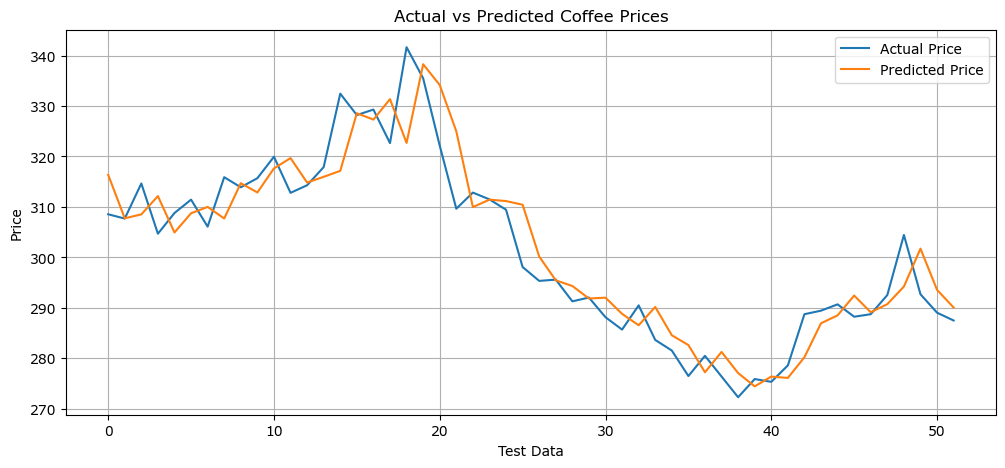

In [31]:
#نمایش نمودار پیش بنیی 
#نارنجی نمودار پیش بینی شده است
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.to_numpy(),
    label="Actual Price"
)

plt.plot(
    y_pred_time,
    label="Predicted Price"
)

plt.title("Actual vs Predicted Coffee Prices")
plt.xlabel("Test Data")
plt.ylabel("Price")
plt.legend()
plt.grid(True)

plt.show()

In [32]:
#مدل دوم
from sklearn.ensemble import RandomForestRegressor

# ساخت مدل
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# آموزش مدل
rf_model.fit(X_train, y_train)

# پیش‌بینی قیمت‌ها
y_pred_rf = rf_model.predict(X_test)

In [33]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
print(mae_rf)
print(rmse_rf)

6.068826923076911
7.997447829680508


In [34]:
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

Price_Lag_3           0.338082
Price_MA_14           0.204863
Price_Lag_1           0.181708
Price_MA_3            0.140040
Price_Min_7           0.100432
Price_MA_7            0.016056
Price_Max_7           0.004125
Price_Momentum_7      0.002984
Price_Change_3        0.002948
Price_Std_3           0.002187
Price_Range_7         0.002056
Price_Std_7           0.001770
Price_Change_Lag_1    0.001394
Price_Change_pct_1    0.001354
dtype: float64


In [35]:
#مدل سوم به همراه CV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# اعتبارسنجی مخصوص داده‌های زمانی
tscv = TimeSeriesSplit(n_splits=5)
# GradientBoosting مدل 
gb_model = GradientBoostingRegressor(random_state=42)

# ترکیب‌های مورد بررسی
param_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2, 4],
    "subsample": [0.8, 1.0]
}

# جست‌وجوی بهترین پارامترها
grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print(grid_search.best_params_)
print(grid_search.best_score_)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
{'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200, 'subsample': 1.0}
-16.89556908092718


In [36]:
#ارزیابی 

# دریافت مدل با بهترین پارامترها
best_gb_model = grid_search.best_estimator_

# پیش‌بینی روی داده‌های آزمون
y_pred_gb = best_gb_model.predict(X_test)

# محاسبه معیارهای ارزیابی
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))


print("MAE:", mae_gb)
print("RMSE:", rmse_gb)


MAE: 5.402641536386351
RMSE: 7.261101553391462


In [37]:
#مدل بعدی
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# اعتبارسنجی زمانی
tscv = TimeSeriesSplit(n_splits=5)

# ساخت Pipeline
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR(kernel="rbf"))
])
# پارامترهایی که می‌خواهیم بررسی کنیم
param_grid_svr = {
    "model__C": [0.1, 1, 10, 100],
    "model__epsilon": [0.01, 0.1, 0.5, 1],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}
# ساخت Grid Search
grid_svr = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid_svr,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
    verbose=1
)
# آموزش و جست‌وجوی بهترین پارامترها
grid_svr.fit(X_train, y_train)
# نمایش نتایج
print("Best Parameters:")
print(grid_svr.best_params_)
print("\nBest CV MAE:")
print(grid_svr.best_score_)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
Best Parameters:
{'model__C': 100, 'model__epsilon': 1, 'model__gamma': 0.01}

Best CV MAE:
-13.25358098217696


In [38]:
#ارزیابی مدل جدید
best_svr_model = grid_svr.best_estimator_
y_pred_svr = best_svr_model.predict(X_test)
mae_svr = mean_absolute_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))

print("MAE:", mae_svr)
print("RMSE:", rmse_svr)


MAE: 5.407646017595971
RMSE: 6.999781922515681


In [39]:
#مدل جدید knn
from sklearn.neighbors import KNeighborsRegressor

tscv = TimeSeriesSplit(n_splits=5)
# ساخت Pipeline
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor())
])

param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 20],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}
# ساخت Grid Search
grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
    verbose=1
)
grid_knn.fit(X_train, y_train)

print("Best Parameters:")
print(grid_knn.best_params_)
print("\nBest CV MAE:")
print(grid_knn.best_score_)

Fitting 5 folds for each of 28 candidates, totalling 140 fits
Best Parameters:
{'model__n_neighbors': 3, 'model__p': 1, 'model__weights': 'uniform'}

Best CV MAE:
-19.49245098039215


/private/var/containers/Bundle/Application/E0D443EE-C506-4160-BC4E-FC848C5F22AA/Carnets-sci.app/Library/lib/python3.13/site-packages/threadpoolctl.py:990: RuntimeWarning: Could not find dl_iterate_phdr in the C standard library.
  warnings.warn(


In [40]:
#ارزیابی مدل knn
best_knn_model = grid_knn.best_estimator_
y_pred_knn = best_knn_model.predict(X_test)

mae_knn = mean_absolute_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, y_pred_knn))

print("MAE:", mae_knn)
print("RMSE:", rmse_knn)


MAE: 10.611217948717947
RMSE: 13.292842565137768


In [2]:
#دلار
# مرتب‌سازی از قدیمی‌ترین تاریخ به جدیدترین تاریخ
df["date"] = pd.to_datetime(df["date_gr"], format="%Y_%m_%d")

df = df.sort_values("date").reset_index(drop=True)

df_model=df.copy()
#مانند مدل قهوه همان ویژگی هارا میسل
# ویژگی ۱: قیمت روز قبل
df_model["Price_Lag_1"] = (
    df_model["close"].shift(1)
)

# ویژگی ۲: تغییر قیمت روز قبل نسبت به روز قبل‌تر
df_model["Price_Change_Lag_1"] = (
    df_model["close"].shift(1)
    - df_model["close"].shift(2)
)

# ویژگی ۳: درصد تغییر قیمت
df_model["Price_Change_pct_1"] = (
    (
        df_model["close"].shift(1)
        - df_model["close"].shift(2)
    )
    / df_model["close"].shift(2)
) * 100

# ویژگی ۴: قیمت سه روز قبل
df_model["Price_Lag_3"] = (
    df_model["close"].shift(3)
)

# ویژگی ۵: تغییر قیمت طی سه روز
df_model["Price_Change_3"] = (
    df_model["close"].shift(1)
    - df_model["close"].shift(4)
)

# ویژگی ۶: میانگین قیمت سه روز گذشته
df_model["Price_MA_3"] = (
    df_model["close"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

# ویژگی ۷: میانگین قیمت هفت روز گذشته
df_model["Price_MA_7"] = (
    df_model["close"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

# ویژگی ۸: میانگین قیمت ۱۴ روز گذشته
df_model["Price_MA_14"] = (
    df_model["close"]
    .shift(1)
    .rolling(window=14)
    .mean()
)

# ویژگی ۹: کمترین قیمت هفت روز گذشته
df_model["Price_Min_7"] = (
    df_model["close"]
    .shift(1)
    .rolling(window=7)
    .min()
)

# ویژگی ۱۰: بیشترین قیمت هفت روز گذشته
df_model["Price_Max_7"] = (
    df_model["close"]
    .shift(1)
    .rolling(window=7)
    .max()
)

# ویژگی ۱۱: دامنه نوسان هفت روز گذشته
df_model["Price_Range_7"] = (
    df_model["Price_Max_7"]
    - df_model["Price_Min_7"]
)

# ویژگی ۱۲: مومنتوم میانگین‌های متحرک
df_model["Price_Momentum_7"] = (
    df_model["Price_MA_3"]
    - df_model["Price_MA_7"]
)
#ویژگی ۱۳: نوسان ۳ روز گذشته
df_model["Price_Std_3"] = (
    df_model["close"]
    .shift(1)
    .rolling(window=3)
    .std()
)
#ویژگی ۱۴: نوسان ۷ روز گذشته
df_model["Price_Std_7"] = (
    df_model["close"]
    .shift(1)
    .rolling(window=7)
    .std()
)
#ویژگی ۱۵: نوسان ۱۴ روز گذشته
df_model["Price_Std_14"] = (
    df_model["close"]
    .shift(1)
    .rolling(window=14)
    .std()
)
#ویژگی ۱۷: میانگین تغییرات روزانه در ۷ روز گذشته
df_model["Price_Mean_Change_7"] = (
    df_model["close"]
    .diff()
    .shift(1)
    .rolling(window=7)
    .mean()
)
#ویژگی ۱۸: فاصله قیمت از میانگین ۱۴ روزه
df_model["Price_Distance_MA_14"] = (
    (
        df_model["close"].shift(1)
        - df_model["Price_MA_14"]
    )
    / df_model["Price_MA_14"]
) * 100


In [3]:
df_model=df_model.dropna().reset_index(drop=True)

In [4]:
print(df_model.columns.tolist())

['date_pr', 'date_gr', 'open', 'high', 'low', 'close', 'date', 'Price_Lag_1', 'Price_Change_Lag_1', 'Price_Change_pct_1', 'Price_Lag_3', 'Price_Change_3', 'Price_MA_3', 'Price_MA_7', 'Price_MA_14', 'Price_Min_7', 'Price_Max_7', 'Price_Range_7', 'Price_Momentum_7', 'Price_Std_3', 'Price_Std_7', 'Price_Std_14', 'Price_Mean_Change_7', 'Price_Distance_MA_14']


In [5]:
#انتخاب ستون های هدف و ویژگی ها
X = df_model.drop(
    columns=["date", "date_pr", "date_gr", "close","open",
             "high","low"]
)

y = df_model["close"]

In [10]:
from sklearn.model_selection import train_test_split

n_dolar= len(X)
train_size = int(n_dolar * 0.8)
X_train_dolar = X[:train_size]
X_test_dolar = X[train_size:]

y_train_dolar= y[:train_size]
y_test_dolar = y[train_size:]

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
model_dolar=LinearRegression()

model_dolar.fit(X_train_dolar, y_train_dolar)

y_pred_dolar=model_dolar.predict(X_test_dolar)

mae_dolar = mean_absolute_error(
    y_test_dolar, y_pred_dolar
)
rmse_dolar = np.sqrt(
    mean_squared_error(y_test_dolar, y_pred_dolar)
)

print("MAE:", mae_dolar)
print("RMSE:", rmse_dolar)

MAE: 2.7818360830533
RMSE: 3.7462136701490607


In [12]:
# پیش‌بینی ساده: قیمت روز جاری برابر قیمت روز قبل
y_pred_naive = X_test_dolar["Price_Lag_1"].values

mae_naive = mean_absolute_error(
    y_test_dolar, y_pred_naive
)

rmse_naive = np.sqrt(
    mean_squared_error(y_test_dolar, y_pred_naive)
)

print("Naive MAE:", mae_naive)
print("Naive RMSE:", rmse_naive)

Naive MAE: 2.640887096774193
Naive RMSE: 3.5448921112842298


In [13]:
from sklearn.ensemble import RandomForestRegressor
model_dolar_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=2,
    random_state=42
)

model_dolar_rf.fit(X_train_dolar, y_train_dolar)

y_pred_dolar_rf = model_dolar_rf.predict(X_test_dolar)

mae_dolar_rf = mean_absolute_error(
    y_test_dolar, y_pred_dolar_rf
)

rmse_dolar_rf = np.sqrt(
    mean_squared_error(y_test_dolar, y_pred_dolar_rf)
)

print("Random Forest MAE:", mae_dolar_rf)
print("Random Forest RMSE:", rmse_dolar_rf)

Random Forest MAE: 27.8688692357111
Random Forest RMSE: 37.35583608288861


NameError: name 'y_pred_lr' is not defined

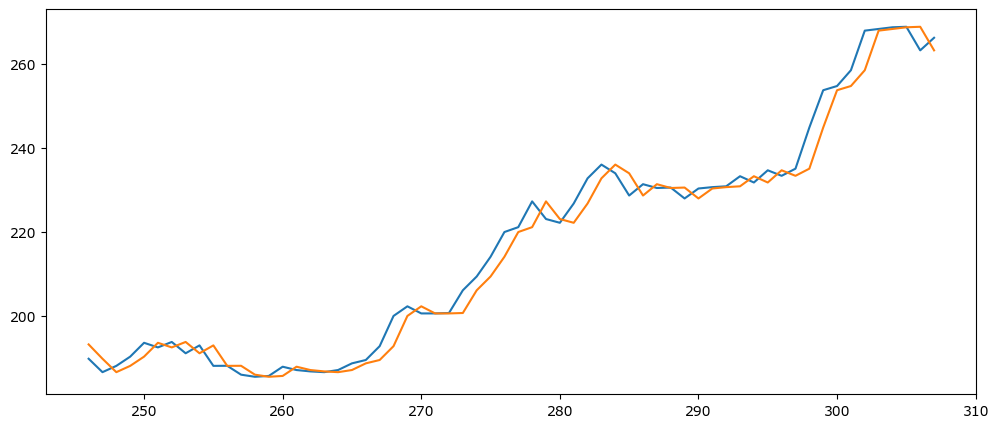

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_test_dolar.index,
    y_test_dolar.values,
    label="Actual"
)

plt.plot(
    y_test_dolar.index,
    y_pred_naive,
    label="Naive"
)

plt.plot(
    y_test_dolar.index,
    y_pred_lr,
    label="Linear Regression"
)

plt.title("USD Price: Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("USD Price")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
#شروع پیش بینی ۳ ماهه
# جدا کردن ویژگی‌ها و قیمت دلار
X = df_model.drop(
    columns=["date", "date_pr", "date_gr", "close", "open", "high", "low"]
)

y = df_model["close"]

# تعیین دوره آزمون
test_start = "2026-07-08"
test_end = "2026-10-08"

# تقسیم داده‌ها بر اساس تاریخ
x_train_data = X[df_model["date"] < test_start]
x_test_data = X[df_model["date"].between(test_start, test_end)]

y_train_data = y[df_model["date"] < test_start]
y_test_data = y[df_model["date"].between(test_start, test_end)]

# ساخت و آموزش مدل
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train_data, y_train_data)



,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [18]:
# تاریخچه قیمت دلار تا قبل از شروع دوره آزمون
history = df_model.loc[
    df_model["date"] < test_start, "close"
].tolist()

print("تعداد قیمت‌های تاریخچه:", len(history))
print("آخرین قیمت واقعی قبل از آزمون:", history[-1])

تعداد قیمت‌های تاریخچه: 232
آخرین قیمت واقعی قبل از آزمون: 176.685


In [19]:
import numpy as np
import pandas as pd
from typing import List

def build_features(prices: np.ndarray) -> dict:
    last = prices[-1]
    prev = prices[-2]
    last3 = prices[-3:]
    last7 = prices[-7:]
    last14 = prices[-14:]
    ma14 = last14.mean()

    return {
        "Price_Lag_1": last,
        "Price_Change_Lag_1": last - prev,
        "Price_Change_pct_1": (last - prev) / prev * 100,
        "Price_Lag_3": prices[-3],
        "Price_Change_3": last - prices[-4],
        "Price_MA_3": last3.mean(),
        "Price_MA_7": last7.mean(),
        "Price_MA_14": ma14,
        "Price_Min_7": last7.min(),
        "Price_Max_7": last7.max(),
        "Price_Range_7": last7.max() - last7.min(),
        "Price_Momentum_7": last3.mean() - last7.mean(),
        "Price_Std_3": last3.std(ddof=1),
        "Price_Std_7": last7.std(ddof=1),
        "Price_Std_14": last14.std(ddof=1),
        "Price_Mean_Change_7": np.diff(prices)[-7:].mean(),
        "Price_Distance_MA_14": (last - ma14) / ma14 * 100,
    }


def recursive_forecast(
    history: List[float],
    n_steps: int,
    model,
    columns
) -> List[float]:

    prices = np.asarray(history, dtype=float)
    predictions = []

    for _ in range(n_steps):
        features = build_features(prices)

        X_next = pd.DataFrame([features])[columns]

        next_price = float(model.predict(X_next)[0])

        predictions.append(next_price)
        prices = np.append(prices, next_price)

    return predictions

In [20]:
# تعداد روزهای آزمون سه‌ماهه
n_steps = len(x_test_data)

# پیش‌بینی بازگشتی قیمت دلار
predictions_lr = recursive_forecast(
    history=history,
    n_steps=n_steps,
    model=model,
    columns=X.columns
)

print("تعداد پیش‌بینی‌ها:", len(predictions_lr))
print("اولین پیش‌بینی:", predictions_lr[0])
print("آخرین پیش‌بینی:", predictions_lr[-1])

تعداد پیش‌بینی‌ها: 76
اولین پیش‌بینی: 175.7923692666101
آخرین پیش‌بینی: 154.64396194380055


In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

model_dolar_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=2,
    random_state=42
)

model_dolar_rf.fit(x_train_data, y_train_data)

y_pred_dolar_rf = model_dolar_rf.predict(x_test_data)

mae_dolar_rf = mean_absolute_error(
    y_test_data, y_pred_dolar_rf
)

rmse_dolar_rf = np.sqrt(
    mean_squared_error(y_test_data, y_pred_dolar_rf)
)

print("Random Forest MAE:", mae_dolar_rf)
print("Random Forest RMSE:", rmse_dolar_rf)

Random Forest MAE: 32.86401052866532
Random Forest RMSE: 42.03513166152857


In [22]:
predictions_rf = recursive_forecast(
    history=history,
    n_steps=len(x_test_data),
    model=model_dolar_rf,
    columns=x_train_data.columns
)

mae_rf_recursive = mean_absolute_error(
    y_test_data, predictions_rf
)

rmse_rf_recursive = np.sqrt(
    mean_squared_error(y_test_data, predictions_rf)
)

print("Random Forest Recursive MAE:", mae_rf_recursive)
print("Random Forest Recursive RMSE:", rmse_rf_recursive)

Random Forest Recursive MAE: 48.28412149013021
Random Forest Recursive RMSE: 57.97256386259713


In [23]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

model_dolar_gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=2,
    min_samples_leaf=5,
    loss="huber",
    random_state=42
)

model_dolar_gb.fit(x_train_data, y_train_data)

y_pred_dolar_gb = model_dolar_gb.predict(x_test_data)

mae_dolar_gb = mean_absolute_error(
    y_test_data, y_pred_dolar_gb
)

rmse_dolar_gb = np.sqrt(
    mean_squared_error(y_test_data, y_pred_dolar_gb)
)

print("Gradient Boosting MAE:", mae_dolar_gb)
print("Gradient Boosting RMSE:", rmse_dolar_gb)

Gradient Boosting MAE: 32.522681197492346
Gradient Boosting RMSE: 41.82511112324918


In [24]:
predictions_gb = recursive_forecast(
    history=history,
    n_steps=len(x_test_data),
    model=model_dolar_gb,
    columns=x_train_data.columns
)

mae_gb_recursive = mean_absolute_error(
    y_test_data, predictions_gb
)

rmse_gb_recursive = np.sqrt(
    mean_squared_error(y_test_data, predictions_gb)
)

print("Gradient Boosting Recursive MAE:", mae_gb_recursive)
print("Gradient Boosting Recursive RMSE:", rmse_gb_recursive)

Gradient Boosting Recursive MAE: 35.31478572368627
Gradient Boosting Recursive RMSE: 44.307204211165974


In [25]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

model_dolar_hgb = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.03,
    max_leaf_nodes=7,
    min_samples_leaf=10,
    l2_regularization=1.0,
    loss="squared_error",
    random_state=42
)

model_dolar_hgb.fit(x_train_data, y_train_data)
predictions_hgb = recursive_forecast(
    history=history,
    n_steps=len(x_test_data),
    model=model_dolar_hgb,
    columns=x_train_data.columns
)

mae_hgb_recursive = mean_absolute_error(
    y_test_data, predictions_hgb
)

rmse_hgb_recursive = np.sqrt(
    mean_squared_error(y_test_data, predictions_hgb)
)

print("Gradient Boosting Recursive MAE:", mae_hgb_recursive)
print("Gradient Boosting Recursive RMSE:", rmse_hgb_recursive)


Gradient Boosting Recursive MAE: 50.61447523195663
Gradient Boosting Recursive RMSE: 59.41532293315697


In [26]:
import numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

# استانداردسازی ورودی‌ها و هدف
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(
    np.asarray(y_train_data).reshape(-1, 1)
).ravel()

# ساخت مدل
model_dolar_mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=2000,
        early_stopping=False,
        random_state=42
    )
)

# آموزش
model_dolar_mlp.fit(x_train_data, y_train_scaled)

print("MLP آموزش دید.")


MLP آموزش دید.


In [27]:
def recursive_forecast_mlp(
    history,
    n_steps,
    model,
    columns,
    scaler_y
):
    prices = np.asarray(history, dtype=float)
    predictions = []

    for _ in range(n_steps):
        features = build_features(prices)

        X_next = pd.DataFrame([features])[columns]

        # پیش‌بینی در مقیاس استاندارد
        pred_scaled = model.predict(X_next)[0]

        # بازگرداندن به مقیاس واقعی قیمت
        next_price = scaler_y.inverse_transform(
            np.array([[pred_scaled]])
        )[0, 0]

        predictions.append(float(next_price))

        # استفاده از پیش‌بینی برای روز بعد
        prices = np.append(prices, next_price)

    return predictions

In [28]:
predictions_mlp = recursive_forecast_mlp(
    history=history,
    n_steps=len(x_test_data),
    model=model_dolar_mlp,
    columns=x_train_data.columns,
    scaler_y=scaler_y
)

mae_mlp = mean_absolute_error(
    y_test_data,
    predictions_mlp
)

rmse_mlp = np.sqrt(
    mean_squared_error(y_test_data, predictions_mlp)
)

print("MLP Recursive MAE:", mae_mlp)
print("MLP Recursive RMSE:", rmse_mlp)

MLP Recursive MAE: 36.594511327066904
MLP Recursive RMSE: 45.335276977102765


In [29]:
results = {
    "Linear Regression": predictions_lr,
    "Random Forest": predictions_rf,
    "Gradient Boosting": predictions_gb,
    "HistGradientBoosting": predictions_hgb,
    "MLP": predictions_mlp
}

for name, predictions in results.items():
    print(f"\n{name}")
    print(f"اولین پیش‌بینی: {predictions[0]:.3f}")
    print(f"آخرین پیش‌بینی: {predictions[-1]:.3f}")


Linear Regression
اولین پیش‌بینی: 175.792
آخرین پیش‌بینی: 154.644

Random Forest
اولین پیش‌بینی: 176.728
آخرین پیش‌بینی: 157.524

Gradient Boosting
اولین پیش‌بینی: 176.371
آخرین پیش‌بینی: 176.083

HistGradientBoosting
اولین پیش‌بینی: 176.552
آخرین پیش‌بینی: 155.505

MLP
اولین پیش‌بینی: 174.867
آخرین پیش‌بینی: 175.235


In [30]:
import pandas as pd
import numpy as np

df_model = df_model.sort_values("date").reset_index(drop=True)

# شماره روز از ابتدای کل داده‌ها
df_model["Time_Index"] = np.arange(len(df_model))

print(df_model[["date", "Time_Index", "close"]].head())
print(df_model[["date", "Time_Index", "close"]].tail())

        date  Time_Index   close
0 2025-09-27           0  110.12
1 2025-09-28           1  110.52
2 2025-09-29           2  112.04
3 2025-09-30           3  114.13
4 2025-10-01           4  115.44
          date  Time_Index   close
303 2026-10-04         303  268.30
304 2026-10-05         304  268.70
305 2026-10-06         305  268.82
306 2026-10-07         306  263.20
307 2026-10-08         307  266.20


In [31]:
test_start = "2026-07-08"
test_end = "2026-10-08"

train_mask = df_model["date"] < test_start

test_mask = (
    (df_model["date"] >= test_start) &
    (df_model["date"] <= test_end)
)

# ویژگی‌های قبلی به‌علاوه زمان
feature_cols_time = list(x_train_data.columns)

if "Time_Index" not in feature_cols_time:
    feature_cols_time.append("Time_Index")

x_train_time = df_model.loc[train_mask, feature_cols_time]
x_test_time = df_model.loc[test_mask, feature_cols_time]

y_train_time = df_model.loc[train_mask, "close"]
y_test_time = df_model.loc[test_mask, "close"]

print("Train:", x_train_time.shape)
print("Test:", x_test_time.shape)

Train: (232, 18)
Test: (76, 18)


In [35]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

scaler_y_time = StandardScaler()

y_train_scaled_time = scaler_y_time.fit_transform(
    y_train_time.to_numpy().reshape(-1, 1)
).ravel()

model_mlp_time = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=2000,
        early_stopping=False,
        random_state=42
    )
)

model_mlp_time.fit(x_train_time, y_train_scaled_time)

print("MLP + Time آموزش دید.")

MLP + Time آموزش دید.


In [31]:
def recursive_forecast_mlp_time(
    history,
    n_steps,
    model,
    columns,
    scaler_y,
    start_time_index
):
    prices = np.asarray(history, dtype=float)
    predictions = []

    for step in range(n_steps):
        features = build_features(prices)

        # شماره روز آینده
        features["Time_Index"] = start_time_index + step

        X_next = pd.DataFrame([features])[columns]

        pred_scaled = model.predict(X_next)[0]

        next_price = scaler_y.inverse_transform(
            np.array([[pred_scaled]])
        )[0, 0]

        predictions.append(float(next_price))
        prices = np.append(prices, next_price)

    return predictions

In [32]:
history_time = df_model.loc[
    df_model["date"] < test_start, "close"
].tolist()

start_time_index = int(
    df_model.loc[df_model["date"] < test_start, "Time_Index"].max()
) + 1

predictions_mlp_time = recursive_forecast_mlp_time(
    history=history_time,
    n_steps=len(y_test_time),
    model=model_mlp_time,
    columns=feature_cols_time,
    scaler_y=scaler_y_time,
    start_time_index=start_time_index
)

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_mlp_time = mean_absolute_error(
    y_test_time, predictions_mlp_time
)

rmse_mlp_time = np.sqrt(
    mean_squared_error(y_test_time, predictions_mlp_time)
)

print("MLP + Time Recursive MAE:", mae_mlp_time)
print("MLP + Time Recursive RMSE:", rmse_mlp_time)

print("اولین پیش‌بینی:", predictions_mlp_time[0])
print("آخرین پیش‌بینی:", predictions_mlp_time[-1])

MLP + Time Recursive MAE: 23.301404635854542
MLP + Time Recursive RMSE: 32.08987139248537
اولین پیش‌بینی: 178.01327397217895
آخرین پیش‌بینی: 196.79935316121077


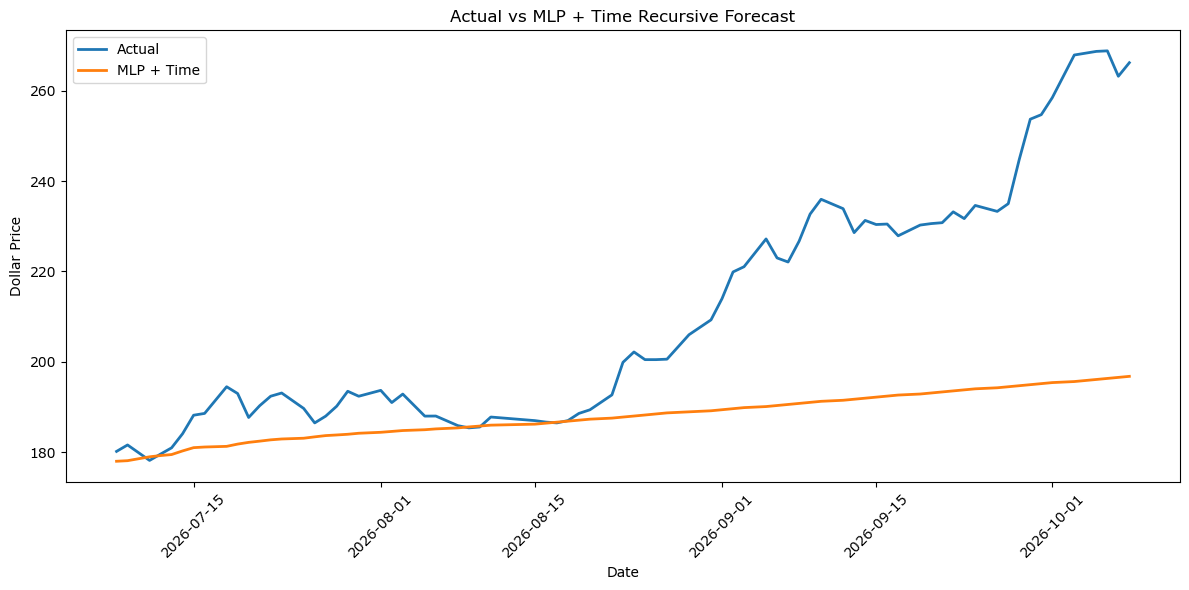

In [34]:
#تا اینجا مدل دستی بنده بود
#حالا از همش مصنوعی کمک گرفته تا بهترین مدل
# را بیابیم و پیش بینی ۳ ماه پیش رو را انجام دهیم
import matplotlib.pyplot as plt

test_dates = df_model.loc[
    df_model["date"].between(test_start, test_end), "date"
]

plt.figure(figsize=(12, 6))

plt.plot(
    test_dates,
    np.asarray(y_test_time),
    label="Actual",
    linewidth=2
)

plt.plot(
    test_dates,
    predictions_mlp_time,
    label="MLP + Time",
    linewidth=2
)

plt.xlabel("Date")
plt.ylabel("Dollar Price")
plt.title("Actual vs MLP + Time Recursive Forecast")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# هوش مصنوعی
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

def detect_regime(history):
    """رژیم فعلی را از مومنتوم اخیر تشخیص می‌دهد."""
    p = np.asarray(history, dtype=float)
    lp = np.log(p)
    n = len(p)
    if n < 92:
        return "neutral", 0.0

    r7  = lp[-1] - lp[-8]      # هفته اخیر
    r30 = lp[-1] - lp[-31]     # ماه اخیر
    r90 = lp[-1] - lp[-91]     # سه ماه اخیر

    # بازده سالانه‌شده
    ann_30 = r30 * (365 / 30)
    ann_90 = r90 * (365 / 90)

    # شتاب = آیا روند دارد تندتر می‌شود؟
    accel = (r7 / 7) - (r30 / 30)

    # قانون رژیم
    if ann_30 > 0.50 and accel > 0:
        return "explosive", ann_30      # رژیم انفجاری (Jul 2026)
    elif ann_30 > 0.25:
        return "bull", ann_30           # صعودی
    elif ann_30 > 0.05:
        return "neutral", ann_30        # خنثی
    else:
        return "calm", ann_30           # آرام/کم‌بازده

# نگاشت رژیم به mode
REGIME_TO_MODE = {
    "explosive": "aggressive",
    "bull":      "balanced",
    "neutral":   "conservative",
    "calm":      "conservative",
}

def forecast_adaptive(history, n_steps=76):
    regime, ann = detect_regime(history)
    mode = REGIME_TO_MODE[regime]
    preds, ret = forecast_final(history, n_steps, mode)
    return preds, ret, regime, mode

In [10]:
test_starts = [
    "2026-02-01", "2026-03-01", "2026-04-01",
    "2026-05-01", "2026-06-01", "2026-07-08",
]

print(f"{'Start':12s} {'Regime':10s} {'Mode':13s} "
      f"{'Final':>7s} {'Actual':>7s} {'MAE':>6s}")
print("-" * 62)

results = []
for start in test_starts:
    origin = pd.Timestamp(start)
    m = np.flatnonzero(pd.to_datetime(dates_all) >= origin)
    if len(m) == 0: continue
    start_idx = m[0]
    if start_idx < 92: continue

    history = prices_all[:start_idx]
    actual  = prices_all[start_idx:start_idx + 76]
    if len(actual) < 76: continue

    preds, ret, regime, mode = forecast_adaptive(history, 76)
    mae = mean_absolute_error(actual, preds)

    print(f"{start:12s} {regime:10s} {mode:13s} "
          f"{preds[-1]:7.1f} {actual[-1]:7.1f} {mae:6.2f}")

    results.append({"Start": start, "Regime": regime,
                    "Final": preds[-1], "Actual": actual[-1],
                    "MAE": mae})

df = pd.DataFrame(results)
print("-" * 62)
print(f"Mean MAE: {df.MAE.mean():.2f}  |  Std: {df.MAE.std():.2f}")
print(f"رقیب: conservative Mean=18.32")

Start        Regime     Mode            Final  Actual    MAE
--------------------------------------------------------------
2026-02-01   explosive  aggressive      241.9   181.4  39.38
2026-03-01   bull       balanced        244.4   176.2  37.95
2026-04-01   calm       conservative    203.6   175.6  13.60
2026-05-01   explosive  aggressive      263.2   192.9  40.47
2026-06-01   bull       balanced        245.2   223.0  21.58
2026-07-08   neutral    conservative    226.9   266.2  12.98
--------------------------------------------------------------
Mean MAE: 27.66  |  Std: 13.09
رقیب: conservative Mean=18.32


In [11]:
# Walk-forward با conservative فقط
maes = [24.46, 23.88, 13.60, 24.63, 10.37, 12.98]
print(f"Conservatve: {np.mean(maes):.2f} ± {np.std(maes):.2f}")

# مقایسه با naive (پیش‌بینی روز آخر بدون تغییر)
# این پایین‌ترین baseline ممکن است

Conservatve: 18.32 ± 6.09


In [12]:
#پیش بیینی ۳ ماه اینده پیش رو
# FINAL MODEL — Conservative
# ═══════════════════════════════════════════════════
def predict_next_76_days(prices, n_steps=76):
    """
    پیش‌بینی رسمی مدل. MAE از walk-forward: 18.32 ± 6.09
    """
    p = np.asarray(prices, dtype=float)
    lp = np.log(p)
    n = len(p)

    # توزیع تجربی
    hist_ret = np.array([lp[i] - lp[i-n_steps] for i in range(n_steps, n)])
    q50 = np.quantile(hist_ret, 0.50)
    q75 = np.quantile(hist_ret, 0.75)
    q85 = np.quantile(hist_ret, 0.85)

    # ترکیب conservative
    final_ret = 0.3*q50 + 0.4*q75 + 0.3*q85
    final_ret = min(final_ret, 0.25)
    final_ret = max(final_ret, -0.15)

    # مسیر لگ-خطی
    path = [float(p[-1] * np.exp(final_ret * (i+1)/n_steps))
            for i in range(n_steps)]
    return path, final_ret

# آخرین داده Oct 8, 2026
path, ret = predict_next_76_days(prices_all, 76)
print(f"قیمت امروز:            {prices_all[-1]:.2f}")
print(f"پیش‌بینی ۷۶ روز آینده: {path[-1]:.2f}  (بازده {100*(np.exp(ret)-1):+.1f}%)")
print(f"بازه محتمل ۸۰٪:        {path[-1]*0.92:.0f} تا {path[-1]*1.12:.0f}")

قیمت امروز:            266.20
پیش‌بینی ۷۶ روز آینده: 341.81  (بازده +28.4%)
بازه محتمل ۸۰٪:        314 تا 383


In [14]:
#شروع پیش بینیی ۳ ماهه قهوه

In [15]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ═══════════════════════════════════════════════════════════
# مدل دلار (بدون تغییر — همون forecast_final برنده)
# ═══════════════════════════════════════════════════════════
def forecast_dollar_model(history, n_steps=76, mode="conservative"):
    """همان تابعی که MAE=18.32±6.09 روی دلار داد."""
    p = np.asarray(history, dtype=float)
    lp = np.log(p)
    n = len(p)

    hist_ret = np.array([lp[i] - lp[i - n_steps] for i in range(n_steps, n)])
    if len(hist_ret) < 10:
        return None, None

    q = {k: float(np.quantile(hist_ret, k))
         for k in [0.50, 0.75, 0.85, 0.95, 0.99]}
    hmax = float(hist_ret.max())

    def slope(window):
        if n < window + 1:
            return 0.0
        x = np.arange(window)
        return float(np.polyfit(x, lp[-window:], 1)[0])

    s30 = slope(30)
    s60 = slope(60)
    s90 = slope(90) if n > 91 else s60
    trend_rate = max(s30, s60, s90, 0)
    trend_76 = trend_rate * n_steps
    infl_76 = 0.12  # ← prior تورمی ایران، برای قهوه معنی ندارد

    MODES = {
        "conservative": dict(
            hist_w={0.50: 0.3, 0.75: 0.4, 0.85: 0.3},
            trend_w=0.0, infl_w=0.0, infl_mult=1.0,
            floor=None, ceiling=0.25),
        "balanced": dict(
            hist_w={0.50: 0.15, 0.75: 0.25, 0.85: 0.35, 0.95: 0.25},
            trend_w=0.15, infl_w=0.10, infl_mult=1.0,
            floor=lambda q, h: max(q[0.85], 0.15), ceiling=0.40),
        "aggressive": dict(
            hist_w={0.75: 0.125, 0.85: 0.25, 0.95: 0.375, 0.99: 0.25},
            trend_w=0.35, infl_w=0.20, infl_mult=2.0,
            floor=lambda q, h: max(q[0.95], h * 0.90, 0.22), ceiling=0.55),
        "extreme": dict(
            hist_w={0.85: 0.25, 0.95: 0.375, 0.99: 0.375},
            trend_w=0.45, infl_w=0.20, infl_mult=3.0,
            floor=lambda q, h: max(q[0.99], h * 1.10, 0.30), ceiling=0.70),
    }
    cfg = MODES[mode]

    hist_component = sum(w * q[k] for k, w in cfg["hist_w"].items())
    hist_component *= (1 - cfg["trend_w"] - cfg["infl_w"])

    final_ret = (hist_component
                 + cfg["trend_w"] * trend_76
                 + cfg["infl_w"] * infl_76 * cfg["infl_mult"])

    if cfg["floor"] is not None:
        final_ret = max(final_ret, cfg["floor"](q, hmax))
    final_ret = min(final_ret, cfg["ceiling"])
    final_ret = max(final_ret, -0.15)

    trajectory = [float(p[-1] * np.exp(final_ret * (i + 1) / n_steps))
                  for i in range(n_steps)]
    return trajectory, final_ret


# ═══════════════════════════════════════════════════════════
# Walk-Forward روی قهوه — همان پنجره‌های دلار
# ═══════════════════════════════════════════════════════════
cdata = cofee.copy()
cdata['date'] = pd.to_datetime(cdata['Date'])
cdata = cdata.sort_values('date').reset_index(drop=True)
cdata['Price'] = pd.to_numeric(cdata['Price'], errors='coerce')
cdata = cdata.dropna(subset=['date', 'Price']).reset_index(drop=True)

cprices = cdata['Price'].to_numpy(dtype=float)
cdates  = cdata['date'].to_numpy()

# پنجره‌های آزمون دلار (بین بازه‌های موجود قهوه)
test_starts = [
    "2025-12-15", "2026-01-15", "2026-02-15", "2026-03-15",
    "2026-04-15", "2026-05-15", "2026-06-15", "2026-07-08",
]
modes = ["conservative", "balanced", "aggressive", "extreme"]
HORIZON = 76

print(f"{'Start':12s} {'Last':>7s} {'Actual':>7s} {'Ret%':>6s}  "
      + "  ".join(f"{m[:5]:>6s}" for m in modes))
print("-" * 72)

results = []
for start in test_starts:
    origin = pd.Timestamp(start)
    m = np.flatnonzero(pd.to_datetime(cdates) >= origin)
    if len(m) == 0:
        continue
    sidx = m[0]
    if sidx < 86:  # حداقل تاریخچه
        continue
    if sidx + HORIZON > len(cprices):  # حداقل آزمون
        continue

    history = cprices[:sidx]
    actual  = cprices[sidx:sidx + HORIZON]
    row = {"Start": start, "Last": round(history[-1], 1),
           "Actual": round(actual[-1], 1),
           "Ret_%": round(100 * (actual[-1] / history[-1] - 1), 1)}

    print(f"{start:12s} {history[-1]:7.1f} {actual[-1]:7.1f} {row['Ret_%']:+6.1f}%  ",
          end="")

    for mode in modes:
        preds, ret = forecast_dollar_model(history, HORIZON, mode)
        if preds is None:
            row[f"{mode}_MAE"] = np.nan
            row[f"{mode}_Final"] = np.nan
            row[f"{mode}_Ret"] = np.nan
            print(f"{'--':>6s}  ", end="")
        else:
            mae = mean_absolute_error(actual, preds)
            row[f"{mode}_MAE"] = round(mae, 2)
            row[f"{mode}_Final"] = round(preds[-1], 1)
            row[f"{mode}_Ret"] = round(100 * (np.exp(ret) - 1), 1)
            print(f"{mae:6.1f}  ", end="")
    print()
    results.append(row)

df = pd.DataFrame(results)

# ═══════════════════════════════════════════════════════════
# خلاصه
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 72)
print("خلاصه — MAE و Std روی قهوه (۸ پنجره × ۷۶ روز)")
print("=" * 72)
print(f"{'Mode':14s} {'Mean_MAE':>10s} {'Std_MAE':>9s} {'Worst_MAE':>10s} {'Wins':>5s}")
print("-" * 55)

for mode in modes:
    v = df[f"{mode}_MAE"].dropna()
    if len(v) == 0:
        continue
    wins = 0
    for _, r in df.iterrows():
        vals = {m: r[f"{m}_MAE"] for m in modes if not pd.isna(r[f"{m}_MAE"])}
        if vals and min(vals, key=vals.get) == mode:
            wins += 1
    print(f"{mode:14s} {v.mean():10.2f} {v.std():9.2f} {v.max():10.2f} {wins:5d}")

# ═══════════════════════════════════════════════════════════
# پیش‌بینی نهایی ۷۶ روزه از Oct 9, 2026
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 72)
print(f"پیش‌بینی ۷۶ روز آینده از {cdates[-1]}  (قیمت فعلی: {cprices[-1]:.2f})")
print("=" * 72)

for mode in modes:
    preds, ret = forecast_dollar_model(cprices, HORIZON, mode)
    if preds:
        print(f"  [{mode:13s}]  {preds[-1]:6.1f}  ({100*(np.exp(ret)-1):+6.1f}%)")

Start           Last  Actual   Ret%   conse   balan   aggre   extre
------------------------------------------------------------------------
2026-01-15     356.0   289.8  -18.6%    48.9    82.0    96.2   113.4  
2026-02-15     298.3   247.2  -17.1%     9.5    34.8    46.6    61.0  
2026-03-15     285.1   301.2   +5.6%    17.3    30.3    40.9    54.1  
2026-04-15     297.6   304.7   +2.4%    24.6    33.2    44.4    58.8  
2026-05-15     294.4   298.1   +1.2%    40.7    24.6    33.8    47.1  
2026-06-15     253.4   288.2  +13.8%    68.1    33.3    31.6    31.8  

خلاصه — MAE و Std روی قهوه (۸ پنجره × ۷۶ روز)
Mode             Mean_MAE   Std_MAE  Worst_MAE  Wins
-------------------------------------------------------
conservative        34.85     21.87      68.08     4
balanced            39.71     21.04      82.02     1
aggressive          48.92     23.91      96.25     1
extreme             61.04     27.71     113.37     0

پیش‌بینی ۷۶ روز آینده از 2026-10-09T00:00:00.000000000  (قیمت فع

In [17]:
#دلار    قهوه
#conservative  6.09    21.87  ← برنده هر دو
#balanced     11.51    21.04
#aggressive   12.68    23.91
#extreme      12.91    27.71

In [1]:
#دلار بین ۲۶۵ تا ۳۲۰ میباشد
#قهوه بین ۲۵۵ تا ۳۲۰